In [1]:
# Exercice 4 : Apprentissage d'un CNN sur le dataset Fashion-MNIST

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, Input
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import pandas as pd

I0000 00:00:1791815924.489398   42261 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791815924.803404   42261 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791815926.422866   42261 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
# 1. Chargement des données Fashion-MNIST
(X_train_raw, y_train), (X_test_raw, y_test) = datasets.fashion_mnist.load_data()
print("Formes initiales :", X_train_raw.shape, y_train.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Formes initiales : (60000, 28, 28) (60000,)


In [3]:
# Définition des libellés des 10 classes pour l'affichage
class_names = ['T-shirt/top', 'Pantalon', 'Pull', 'Robe', 'Manteau', 
               'Sandale', 'Chemise', 'Sneaker', 'Sac', 'Bottine']

In [4]:
# 2. Prétraitement : Normalisation des pixels de 0-255 à 0-1
X_train = X_train_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

In [5]:
# 3. Ajout de la dimension du canal : (N, 28, 28) devient (N, 28, 28, 1)
X_train = np.expand_dims(X_train, -1)
X_test = np.expand_dims(X_test, -1)

In [7]:
import os
# Désactive l'utilisation du GPU pour forcer TensorFlow à tourner sur le CPU
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

In [8]:
# 4. Construction de l'architecture du CNN
model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

In [9]:
# 5. Compilation du modèle
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# 6. Entraînement du modèle
history = model.fit(
    X_train, y_train, 
    epochs=5, 
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5


W0000 00:00:1791816355.452509   42261 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 20ms/step - accuracy: 0.7476 - loss: 0.6848 - val_accuracy: 0.8417 - val_loss: 0.4231
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.8450 - loss: 0.4296 - val_accuracy: 0.8622 - val_loss: 0.3553
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 21s 25ms/step - accuracy: 0.8722 - loss: 0.3575 - val_accuracy: 0.8822 - val_loss: 0.3134
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.8856 - loss: 0.3194 - val_accuracy: 0.8837 - val_loss: 0.3124
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.8954 - loss: 0.2902 - val_accuracy: 0.9012 - val_loss: 0.2779


In [11]:
# 7. Évaluation finale sur le jeu de test
loss, acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nPrécision sur le test: {acc*100:.2f}%")

313/313 - 1s - 3ms/step - accuracy: 0.8951 - loss: 0.2850

Précision sur le test: 89.51%


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


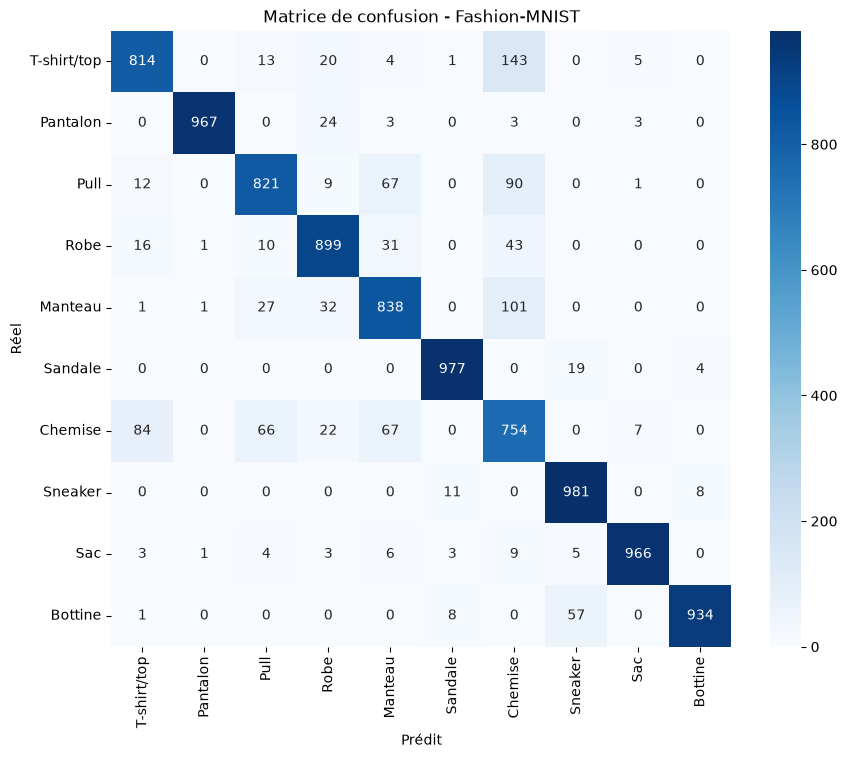

In [12]:
# 8. Prédictions et Matrice de confusion pour identifier les classes confondues
y_pred = np.argmax(model.predict(X_test), axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion - Fashion-MNIST")
plt.show()

In [13]:
# 9. Rapport de classification détaillé
print(classification_report(y_test, y_pred, target_names=class_names))

              precision    recall  f1-score   support

 T-shirt/top       0.87      0.81      0.84      1000
    Pantalon       1.00      0.97      0.98      1000
        Pull       0.87      0.82      0.85      1000
        Robe       0.89      0.90      0.89      1000
     Manteau       0.82      0.84      0.83      1000
     Sandale       0.98      0.98      0.98      1000
     Chemise       0.66      0.75      0.70      1000
     Sneaker       0.92      0.98      0.95      1000
         Sac       0.98      0.97      0.97      1000
     Bottine       0.99      0.93      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



In [ ]:
"""
Les réussites : Sur un total de 1 000 pantalons testés, le modèle en a reconnu correctement 967.
De même pour les Sneakers (981 réussites).

Les confusions (les erreurs du modèle) : Tout ce qui se trouve en dehors de la diagonale représente des erreurs.

La ligne T-shirt/top : le modèle a bien reconnu 814 t-shirts, mais il s'est trompé 143 fois 
en les classant dans la colonne Chemise.

De la même façon, sur la ligne Chemise, le modèle en a confondu 84 avec des T-shirts et 66 avec des Pulls.
"""